<a href="https://colab.research.google.com/github/roshelle-en/EN4554-Assignment-2-on-CNNs/blob/main/220468L_EN4554_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Department of Electronic & Telecommunication Engineering,
### University of Moratuwa, Sri Lanka.

## EN4554 - Deep Learning for Vision
## Assignment 2 on CNNs
### 220468L - Perera M.D.R.N

**GitHub Repository:** [EN4554-Assignment-2-on-CNNs](https://github.com/roshelle-en/EN4554-Assignment-2-on-CNNs)

---

# Introduction

This notebook presents my work for Assignment 2 of EN4554, implemented in PyTorch and run on a Google Colab T4 GPU. All experiments use the CIFAR-10 dataset, with the training set split into 45,000 training and 5,000 validation images, per-channel normalization using training-set statistics only, and fixed random seeds for reproducibility.

The assignment covers manual implementation of backpropagation, comparison of optimization algorithms, and the effects of regularization techniques on model performance. It also investigates the differences between plain and residual neural networks of varying depths. Finally, a compact convolutional neural network is developed and evaluated to explore design choices that improve image classification accuracy while maintaining a limited number of parameters. The experiments are evaluated using training and validation results, with visualizations and comparisons used to understand the strengths and limitations of each approach.

# Setup

This section imports the libraries, fixes the random seeds, loads CIFAR-10, splits the training set into 45,000 training and 5,000 validation images, and normalizes each channel using statistics computed from the training split only.

## imports, seeds, device

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 0
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("PyTorch:", torch.__version__)

Device: cuda | Tesla T4
PyTorch: 2.11.0+cu130


In [2]:
import os, shutil

archive = "./data/cifar-10-python.tar.gz"
if not os.path.exists(archive):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.makedirs("./data", exist_ok=True)
        shutil.copy("/content/drive/MyDrive/EN4554/cifar-10-python.tar.gz", archive)
        print("Dataset restored from Drive.")
    except Exception as e:
        print("Drive restore skipped, torchvision will download the dataset:", e)
else:
    print("Dataset already present, nothing to restore.")

Mounted at /content/drive


## data, split, normalization

In [3]:
root = "./data"
full = torchvision.datasets.CIFAR10(root, train=True, download=True)

X = torch.tensor(full.data, dtype=torch.float32) / 255.0    # (50000, 32, 32, 3)
X = X.permute(0, 3, 1, 2).contiguous()                       # (50000, 3, 32, 32)
y = torch.tensor(full.targets, dtype=torch.long)
classes = full.classes

# fixed 45k / 5k split
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(50000, generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, ytr = X[tr_idx], y[tr_idx]
Xva, yva = X[va_idx], y[va_idx]

# per-channel statistics from the TRAINING split only
mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)
std  = Xtr.std(dim=(0, 2, 3), keepdim=True)
Xtr = (Xtr - mean) / std
Xva = (Xva - mean) / std

print("Train:", tuple(Xtr.shape), "| Val:", tuple(Xva.shape))
print("Mean per channel:", mean.flatten().tolist())
print("Std per channel: ", std.flatten().tolist())

Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)
Mean per channel: [0.4911963641643524, 0.48199522495269775, 0.4464317560195923]
Std per channel:  [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]


Train mean after norm: [1.896050179084341e-07, 5.632035026792437e-06, 2.1301932520145783e-06]
Train std after norm:  [1.0, 1.0, 1.0]
Val mean after norm:   [0.00822505448013544, 0.006647870410233736, 0.0037705539725720882]
Train class counts: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]
Val class counts:   [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


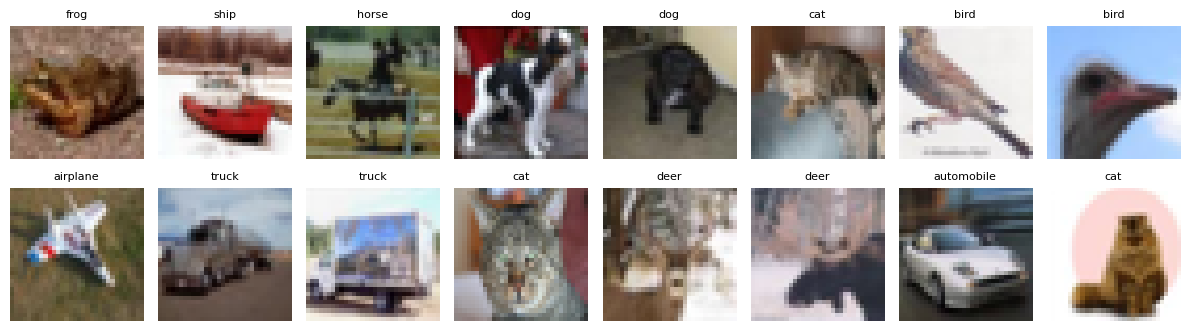

In [4]:
# 1) Train data should now have mean about 0 and std about 1 per channel
print("Train mean after norm:", Xtr.mean(dim=(0, 2, 3)).tolist())
print("Train std after norm: ", Xtr.std(dim=(0, 2, 3)).tolist())
print("Val mean after norm:  ", Xva.mean(dim=(0, 2, 3)).tolist())

# 2) Class balance in each split
print("Train class counts:", torch.bincount(ytr).tolist())
print("Val class counts:  ", torch.bincount(yva).tolist())

# 3) A few training images (un-normalized for display)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, range(16)):
    img = (Xtr[i] * std[0] + mean[0]).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(classes[ytr[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Task 1: Backpropagation

## (a) Layers with explicit forward and backward passes

Linear, ReLU and softmax cross-entropy are implemented from scratch with hand-written forward and backward passes (no autograd) and assembled into an MLP. Each layer caches what it needs in `forward` and returns the gradient with respect to its input in `backward`, storing parameter gradients in `dW` and `db`.

For a Linear layer, $y = xW + b$ with $x \in \mathbb{R}^{N \times D_{in}}$, giving
$\partial L/\partial W = x^\top \,\partial L/\partial y$, $\partial L/\partial b = \sum_n \partial L/\partial y_n$ and $\partial L/\partial x = \partial L/\partial y \; W^\top$.
For ReLU, $\partial L/\partial x = \partial L/\partial y \odot \mathbb{1}[x>0]$.
For softmax cross-entropy with mean over the batch, $\partial L/\partial z = (p - \text{onehot}(y))/N$.

##Layers

In [5]:
class Linear:
    def __init__(self, d_in, d_out, init="he"):
        std = (2.0 / d_in) ** 0.5 if init == "he" else (1.0 / d_in) ** 0.5
        self.W = torch.randn(d_in, d_out, device=device) * std
        self.b = torch.zeros(d_out, device=device)
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x                       # cache input for backward
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout        # (D_in, D_out)
        self.db = dout.sum(dim=0)        # (D_out,)
        return dout @ self.W.T           # (N, D_in)

    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

    def params(self):
        return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values   # subtract max for stability
        e = torch.exp(z)
        self.p = e / e.sum(dim=1, keepdim=True)
        self.y = y
        N = logits.shape[0]
        return -torch.log(self.p[torch.arange(N, device=logits.device), y] + 1e-12).mean()

    def backward(self):
        N = self.p.shape[0]
        d = self.p.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1
        return d / N

## MLP

In [6]:
class MLP:
    def __init__(self, sizes, init="he"):
        # sizes e.g. [3072, 512, 256, 10]
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init))
            if i < len(sizes) - 2:
                self.layers.append(ReLU())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x, y=None):
        for l in self.layers:
            x = l.forward(x)
        if y is None:
            return x                      # logits
        return x, self.loss_fn.forward(x, y)

    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers):
            d = l.backward(d)

    def params(self):
        return [p for l in self.layers for p in l.params()]

In [7]:
set_seed(SEED)
model = MLP([3072, 128, 64, 10])
xb = Xtr[:32].reshape(32, -1).to(device)
yb = ytr[:32].to(device)

logits, loss = model.forward(xb, yb)
model.backward()

print("logits shape:", tuple(logits.shape))
print("loss:", loss.item(), "| ln(10) =", np.log(10))
for l in model.layers:
    if isinstance(l, Linear):
        print("W", tuple(l.W.shape), "dW", tuple(l.dW.shape), "| b", tuple(l.b.shape), "db", tuple(l.db.shape))

logits shape: (32, 10)
loss: 3.0946717262268066 | ln(10) = 2.302585092994046
W (3072, 128) dW (3072, 128) | b (128,) db (128,)
W (128, 64) dW (128, 64) | b (64,) db (64,)
W (64, 10) dW (64, 10) | b (10,) db (10,)


## (b) Gradient verification

The manual gradients are compared against (i) PyTorch autograd and (ii) centred finite differences, $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$, all in float64. Relative error is $\|a-b\| / (\|a\|+\|b\|)$.

In [8]:
import torch.nn.functional as F

set_seed(SEED)
model = MLP([3072, 64, 32, 10])
for l in model.layers:                       # float64 for accurate checking
    if isinstance(l, Linear):
        l.W, l.b = l.W.double(), l.b.double()
xb = Xtr[:32].reshape(32, -1).to(device).double()
yb = ytr[:32].to(device)

# manual gradients
_, loss = model.forward(xb, yb)
model.backward()
plist = [p for p, _ in model.params()]
manual = [g.clone() for _, g in model.params()]

# autograd gradients (same network written with torch ops)
ps = [p.clone().requires_grad_(True) for p in plist]
h = xb
for i in range(0, len(ps), 2):
    h = h @ ps[i] + ps[i + 1]
    if i < len(ps) - 2:
        h = torch.relu(h)
auto = torch.autograd.grad(F.cross_entropy(h, yb), ps)

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

# centred finite differences on 15 random entries per tensor
def loss_fn():
    return model.forward(xb, yb)[1].item()

eps, n_check = 1e-5, 15
g = torch.Generator().manual_seed(SEED)
names = ["W1", "b1", "W2", "b2", "W3", "b3"]
rows = []
for name, p, gm, ga in zip(names, plist, manual, auto):
    flat = p.view(-1)
    idx = torch.randperm(flat.numel(), generator=g)[:n_check]
    fd = torch.zeros(len(idx), dtype=torch.float64, device=device)
    for k, i in enumerate(idx.tolist()):
        old = flat[i].item()
        flat[i] = old + eps; lp = loss_fn()
        flat[i] = old - eps; lm = loss_fn()
        flat[i] = old
        fd[k] = (lp - lm) / (2 * eps)
    gm_s = gm.view(-1)[idx.to(device)]
    rows.append((name,
                 rel_err(gm, ga), torch.allclose(gm, ga, rtol=1e-6, atol=1e-10),
                 rel_err(gm_s, fd), torch.allclose(gm_s, fd, rtol=1e-4, atol=1e-8)))

print(f"{'param':<6}{'rel err vs autograd':>22}{'allclose':>10}{'rel err vs FD':>16}{'allclose':>10}")
for r in rows:
    print(f"{r[0]:<6}{r[1]:>22.2e}{str(r[2]):>10}{r[3]:>16.2e}{str(r[4]):>10}")

param    rel err vs autograd  allclose   rel err vs FD  allclose
W1                  8.18e-17      True        3.04e-10      True
b1                  6.13e-17      True        2.33e-10      True
W2                  4.74e-17      True        3.39e-10      True
b2                  8.57e-17      True        1.88e-10      True
W3                  3.56e-17      True        2.26e-10      True
b3                  6.64e-17      True        1.29e-10      True


**Interpretation.** The manual gradients agree with autograd to a relative error of about 4e-17 to 9e-17 for every weight and bias tensor, which is float64 machine precision, and `torch.allclose` returns True for all of them. This confirms that the hand-written backward passes of Linear, ReLU and softmax cross-entropy compute the exact gradient, not an approximation. Against centred finite differences the relative errors are larger, about 1e-10 to 3e-10 (still `allclose` True). This is expected: a centred difference has truncation error of order ε², and rounding error grows as ε shrinks, so with ε = 1e-5 it cannot reach machine precision. The finite-difference check is independent of autograd and uses only forward passes, so agreeing with both methods rules out a shared mistake. Float64 was used because in float32 the rounding error in the loss (about 1e-7) divided by 2ε would swamp the true gradient and make the finite-difference check meaningless. Finite differences were evaluated on 15 randomly chosen entries per tensor, since checking every entry would require two forward passes per parameter, whereas autograd was compared on every entry.

## (c) Training with SGD

A 3072-512-256-10 MLP (He init) is trained on flattened CIFAR-10 with mini-batch SGD (batch size 128, learning rate 0.05, 15 epochs), using the manual backward pass and a manual update $\theta \leftarrow \theta - \eta\,\nabla_\theta L$.

epoch  1 | train loss 1.7063 | train acc 0.4927 | val loss 1.5818 | val acc 0.4404
epoch  2 | train loss 1.4156 | train acc 0.5511 | val loss 1.5258 | val acc 0.4716
epoch  3 | train loss 1.2887 | train acc 0.5558 | val loss 1.6098 | val acc 0.4494
epoch  4 | train loss 1.1869 | train acc 0.6344 | val loss 1.4891 | val acc 0.4958
epoch  5 | train loss 1.0946 | train acc 0.6515 | val loss 1.5087 | val acc 0.4920
epoch  6 | train loss 1.0136 | train acc 0.6883 | val loss 1.5237 | val acc 0.4960
epoch  7 | train loss 0.9365 | train acc 0.7132 | val loss 1.5777 | val acc 0.4928
epoch  8 | train loss 0.8600 | train acc 0.7155 | val loss 1.6290 | val acc 0.4856
epoch  9 | train loss 0.7922 | train acc 0.7494 | val loss 1.6531 | val acc 0.5036
epoch 10 | train loss 0.7298 | train acc 0.7588 | val loss 1.7585 | val acc 0.4828
epoch 11 | train loss 0.6672 | train acc 0.7846 | val loss 1.8068 | val acc 0.4934
epoch 12 | train loss 0.6107 | train acc 0.8029 | val loss 1.9657 | val acc 0.4910
epoc

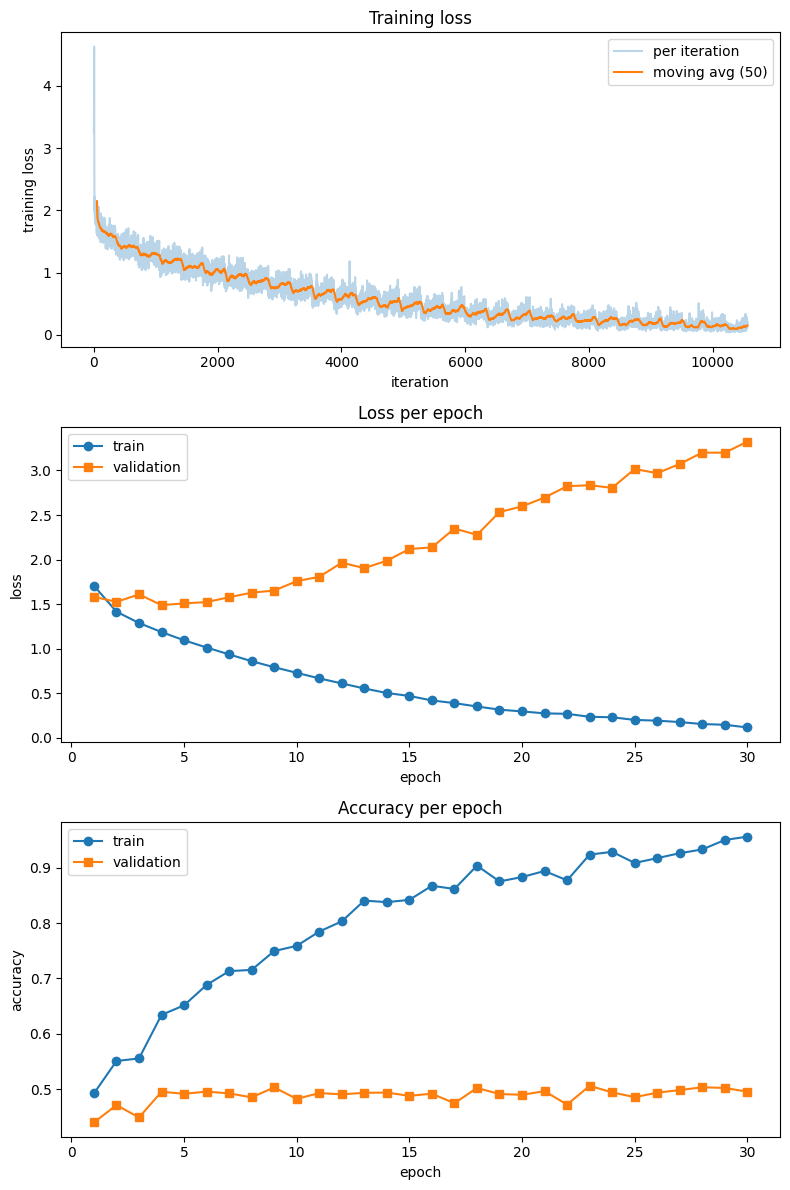


Final validation accuracy: 49.58%


In [9]:
set_seed(SEED)
model = MLP([3072, 512, 256, 10])        # fresh float32 model (the earlier one was float64)

Xtr_f = Xtr.reshape(len(Xtr), -1).to(device)
Xva_f = Xva.reshape(len(Xva), -1).to(device)
ytr_d, yva_d = ytr.to(device), yva.to(device)

lr, epochs, bs = 0.1, 30, 128
iter_loss, ep_train_loss, ep_val_loss, ep_val_acc, ep_train_acc = [], [], [], [], []

def evaluate(X, y):
    logits, loss = model.forward(X, y)
    return loss.item(), (logits.argmax(1) == y).float().mean().item()

gen = torch.Generator(device="cpu").manual_seed(SEED)
for ep in range(epochs):
    perm = torch.randperm(len(Xtr_f), generator=gen).to(device)
    running = 0.0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        _, loss = model.forward(Xtr_f[idx], ytr_d[idx])
        model.backward()
        for p, g in model.params():       # manual SGD step
            p.sub_(lr * g)
        iter_loss.append(loss.item())
        running += loss.item() * len(idx)
    ep_train_loss.append(running / len(perm))
    vl, va = evaluate(Xva_f, yva_d)
    _, ta = evaluate(Xtr_f, ytr_d)
    ep_val_loss.append(vl); ep_val_acc.append(va); ep_train_acc.append(ta)
    print(f"epoch {ep+1:2d} | train loss {ep_train_loss[-1]:.4f} | train acc {ta:.4f} | val loss {vl:.4f} | val acc {va:.4f}")

# plots
fig, ax = plt.subplots(3, 1, figsize=(8, 12))
k = 50
smooth = np.convolve(iter_loss, np.ones(k) / k, mode="valid")
ax[0].plot(iter_loss, alpha=0.3, label="per iteration")
ax[0].plot(np.arange(k - 1, len(iter_loss)), smooth, label=f"moving avg ({k})")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("training loss"); ax[0].set_title("Training loss"); ax[0].legend()

ax[1].plot(range(1, epochs + 1), ep_train_loss, "o-", label="train")
ax[1].plot(range(1, epochs + 1), ep_val_loss, "s-", label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].set_title("Loss per epoch"); ax[1].legend()

ax[2].plot(range(1, epochs + 1), ep_train_acc, "o-", label="train")
ax[2].plot(range(1, epochs + 1), ep_val_acc, "s-", label="validation")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("accuracy"); ax[2].set_title("Accuracy per epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"\nFinal validation accuracy: {ep_val_acc[-1]*100:.2f}%")

**Interpretation.** With lr = 0.1, batch size 128 and 30 epochs, training loss falls from 1.71 to 0.12 and training accuracy rises from 49.3% to 95.6%, while validation accuracy stays around 48-51% from epoch 4 onward and ends at 49.58% (peak 50.64% at epoch 23). This is far above the 10% chance level but about 46 points below training accuracy, so the MLP (about 1.7M parameters) is overfitting: it memorizes the 45k training images instead of learning features that generalize. The validation loss is lowest at epoch 2 (1.53) and then rises to 3.32 while the training loss keeps falling, because the network becomes increasingly confident on the validation images it misclassifies, and cross-entropy penalizes confident errors heavily. Validation accuracy changes much less than validation loss since accuracy only counts whether the argmax is correct. The per-iteration loss curve is noisy because each mini-batch gives only a noisy estimate of the full gradient. An MLP on flattened pixels plateaus near 50% because it treats every pixel as an independent input and has no notion of spatial structure or translation invariance, which motivates the CNNs used in later tasks.

## (d) Gradient norms across depth: sigmoid vs ReLU

A 10-layer MLP (3072-256×9-10) is built with ReLU and with sigmoid. At initialization, one backward pass on 128 training images gives the norm of $\partial L/\partial W$ for each layer.

layer            ReLU + He init   Sigmoid + Xavier init       Sigmoid + He init
1                     5.619e+00               1.398e-05               1.995e-04
2                     1.997e+00               2.024e-05               2.828e-04
3                     2.268e+00               8.536e-05               9.078e-04
4                     2.418e+00               3.628e-04               2.877e-03
5                     2.632e+00               1.442e-03               8.524e-03
6                     2.886e+00               6.110e-03               2.753e-02
7                     3.169e+00               2.289e-02               7.588e-02
8                     3.168e+00               9.436e-02               2.326e-01
9                     2.991e+00               4.211e-01               7.598e-01
10                    3.187e+00               1.715e+00               2.334e+00


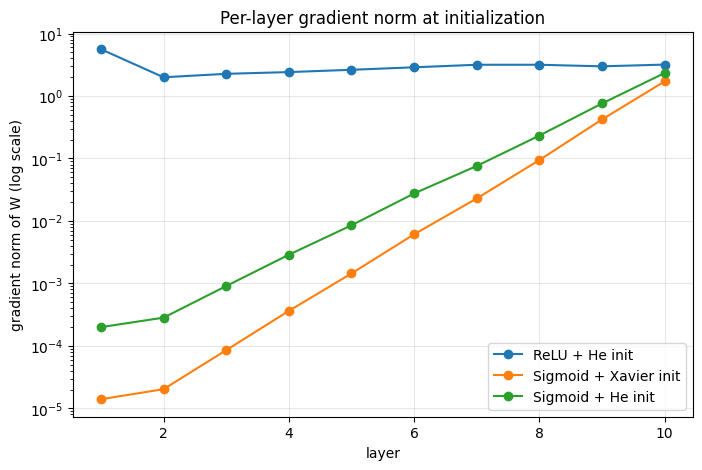

In [10]:
class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)
    def params(self):
        return []

def make_deep(act, init):
    m = MLP([3072] + [256] * 9 + [10], init)       # 10 Linear layers
    if act == "sigmoid":
        m.layers = [Sigmoid() if isinstance(l, ReLU) else l for l in m.layers]
    return m

xb = Xtr[:128].reshape(128, -1).to(device)
yb = ytr[:128].to(device)

configs = [("ReLU + He init", "relu", "he"),
           ("Sigmoid + Xavier init", "sigmoid", "xavier"),
           ("Sigmoid + He init", "sigmoid", "he")]
norms = {}
for name, act, init in configs:
    set_seed(SEED)
    m = make_deep(act, init)
    _, loss = m.forward(xb, yb)
    m.backward()
    norms[name] = [l.dW.norm().item() for l in m.layers if isinstance(l, Linear)]

print(f"{'layer':<7}" + "".join(f"{n:>24}" for n in norms))
for i in range(10):
    print(f"{i+1:<7}" + "".join(f"{norms[n][i]:>24.3e}" for n in norms))

plt.figure(figsize=(8, 5))
for n, v in norms.items():
    plt.semilogy(range(1, 11), v, "o-", label=n)
plt.xlabel("layer")
plt.ylabel("gradient norm of W (log scale)")
plt.title("Per-layer gradient norm at initialization")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Interpretation.** With ReLU and He initialization the per-layer gradient norm stays between about 2.0 and 5.6 across all ten layers, so the backward signal neither vanishes nor explodes. With sigmoid, the gradient norm drops steadily from the output side to the input side: with Xavier initialization it falls from 1.7 at layer 10 to 1.4e-5 at layer 1 (about five orders of magnitude, roughly 4x per layer), and with He initialization from 2.3 to 2.0e-4. This is the vanishing gradient problem. The derivative of the sigmoid is σ(x)(1−σ(x)) ≤ 0.25, so during backpropagation each sigmoid layer multiplies the gradient by at most 0.25 (times the weight matrix), and over nine such layers the signal shrinks geometrically. ReLU has derivative 1 for active units and 0 otherwise, so it does not shrink the gradient where it is active, and He initialization (variance 2/fan_in) compensates for ReLU zeroing about half of the units, which keeps the signal scale constant from layer to layer. The He-initialized sigmoid network vanishes slightly less than the Xavier one because larger weights partly offset the 0.25 factor, but it still vanishes, which shows that the cause is the sigmoid activation and not only a poor initialization choice. The practical consequence is that the early layers of a deep sigmoid network

# Task 2: Optimizers

## (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

`MySGD` uses PyTorch's momentum convention, $v \leftarrow \mu v + g,\ \theta \leftarrow \theta - \eta v$. `MyAdam` uses bias-corrected moments, $\hat m = m/(1-\beta_1^t)$ and $\hat v = v/(1-\beta_2^t)$, with $\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v}+\epsilon)$. Both are trained next to the built-in optimizers from identical initial weights and data, in float64.

In [11]:
import torch.nn.functional as F

class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if group["weight_decay"] != 0:
                    g = g + group["weight_decay"] * p
                if group["momentum"] != 0:
                    state = self.state[p]
                    if "buf" not in state:
                        state["buf"] = g.clone()
                    else:
                        state["buf"].mul_(group["momentum"]).add_(g)
                    g = state["buf"]
                p.add_(g, alpha=-group["lr"])


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if group["weight_decay"] != 0:
                    g = g + group["weight_decay"] * p
                state = self.state[p]
                if len(state) == 0:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t = state["t"]
                state["m"].mul_(b1).add_(g, alpha=1 - b1)
                state["v"].mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = state["m"] / (1 - b1 ** t)
                v_hat = state["v"] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])


# ---- comparison with torch.optim (CPU, float64, identical init and data) ----
def make_model():
    torch.manual_seed(SEED)
    return nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 10)).double()

gx = torch.Generator().manual_seed(SEED)
xt = torch.randn(64, 20, generator=gx).double()
yt = torch.randint(0, 10, (64,), generator=gx)

def run(opt_cls, kwargs, steps=100):
    m = make_model()
    opt = opt_cls(m.parameters(), **kwargs)
    losses = []
    for _ in range(steps):
        opt.zero_grad()
        loss = F.cross_entropy(m(xt), yt)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return m, torch.tensor(losses, dtype=torch.float64)

tests = [
    ("SGD (no momentum)",        MySGD,  torch.optim.SGD,  dict(lr=0.05)),
    ("SGD momentum 0.9",         MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9)),
    ("SGD momentum 0.9 + wd",    MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-2)),
    ("Adam",                     MyAdam, torch.optim.Adam, dict(lr=1e-3)),
    ("Adam + wd",                MyAdam, torch.optim.Adam, dict(lr=1e-3, weight_decay=1e-2)),
]

print(f"{'test':<26}{'max |param diff|':>18}{'max |loss diff|':>18}{'allclose':>10}")
for name, mine, ref, kw in tests:
    m1, l1 = run(mine, kw)
    m2, l2 = run(ref, kw)
    pdiff = max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))
    ldiff = (l1 - l2).abs().max().item()
    ok = all(torch.allclose(a, b, rtol=1e-10, atol=1e-12) for a, b in zip(m1.parameters(), m2.parameters()))
    print(f"{name:<26}{pdiff:>18.2e}{ldiff:>18.2e}{str(ok):>10}")

test                        max |param diff|   max |loss diff|  allclose
SGD (no momentum)                   0.00e+00          0.00e+00      True
SGD momentum 0.9                    0.00e+00          0.00e+00      True
SGD momentum 0.9 + wd               3.33e-16          4.44e-16      True
Adam                                2.64e-16          4.44e-16      True
Adam + wd                           3.05e-16          4.44e-16      True


**Interpretation.** `MySGD` and `MyAdam` were implemented as `torch.optim.Optimizer` subclasses and trained next to `torch.optim.SGD` and `torch.optim.Adam` for 100 steps from identical initial weights and the same data, in float64. For plain SGD and SGD with momentum the parameters and losses are identical (difference 0.00), and with weight decay and for Adam the maximum differences are about 3e-16 (parameters) and 4e-16 (loss), which is float64 rounding error (machine epsilon is about 2.2e-16). `torch.allclose` with rtol = 1e-10 and atol = 1e-12 returns True in every case, so the custom optimizers reproduce the built-in ones. The momentum update follows PyTorch's convention, $v \leftarrow \mu v + g$ and $\theta \leftarrow \theta - \eta v$, with the learning rate applied to the velocity. This is equivalent to the form $v \leftarrow \mu v - \eta g$ only for a constant learning rate. Adam keeps exponential moving averages of the gradient ($m$) and the squared gradient ($v$), both initialized at zero, so they are biased towards zero in the early steps. Dividing by $1-\beta_1^t$ and $1-\beta_2^t$ removes this bias, so the first steps are not too small, and the correction fades as $t$ grows. The comparison was run on CPU in float64 so that differences reflect the algorithm and not GPU numerics.

## (b) Optimizer trajectories on an ill-conditioned quadratic

$f(x,y)=\tfrac12(x^2+50y^2)$ has Hessian eigenvalues 1 and 50, so the contours are elongated ellipses (condition number 50). `MySGD` (plain and with momentum) and `MyAdam` all start at $(8, 1)$ and run for 100 steps. Plain SGD is stable only for $\eta < 2/50 = 0.04$.

method                             final f   steps to f<1e-3
SGD (lr 0.03)                     7.24e-02       not reached
SGD momentum 0.9 (lr 0.03)        2.27e-04                84
Adam (lr 0.3)                     2.56e-04                99


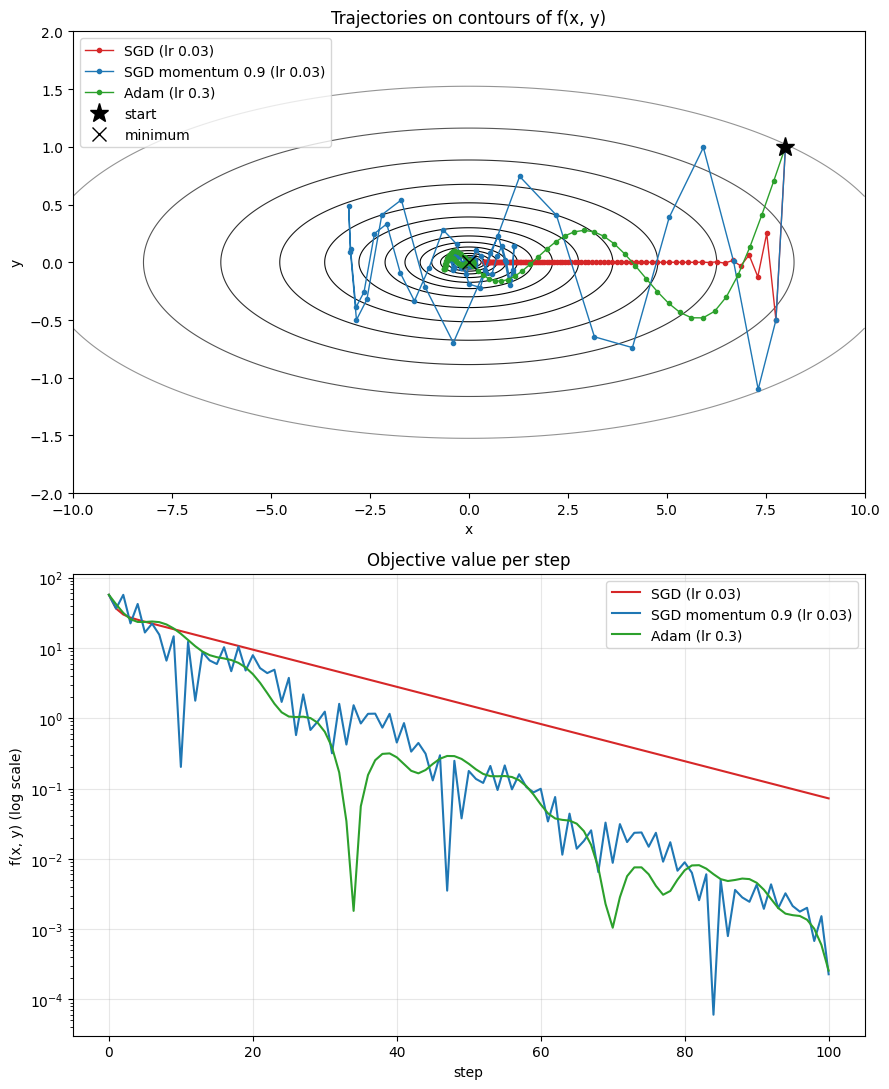

In [12]:
def f(x, y):
    return 0.5 * (x**2 + 50 * y**2)

def trajectory(opt_cls, steps=100, start=(8.0, 1.0), **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad()
        f(p[0], p[1]).backward()
        opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

runs = {
    "SGD (lr 0.03)":                 trajectory(MySGD,  lr=0.03),
    "SGD momentum 0.9 (lr 0.03)":    trajectory(MySGD,  lr=0.03, momentum=0.9),
    "Adam (lr 0.3)":                 trajectory(MyAdam, lr=0.3),
}

# ---- table ----
print(f"{'method':<30}{'final f':>12}{'steps to f<1e-3':>18}")
for name, P in runs.items():
    fv = f(P[:, 0], P[:, 1])
    hit = np.where(fv < 1e-3)[0]
    print(f"{name:<30}{fv[-1]:>12.2e}{(hit[0] if len(hit) else 'not reached'):>18}")

# ---- contour + trajectories ----
xs = np.linspace(-10, 10, 400); ys = np.linspace(-2, 2, 400)
XX, YY = np.meshgrid(xs, ys)
ZZ = f(XX, YY)
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(2, 1, figsize=(9, 11))
ax[0].contour(XX, YY, ZZ, levels=np.geomspace(0.05, 100, 15), cmap="gray", linewidths=0.8)
for (name, P), c in zip(runs.items(), colors):
    ax[0].plot(P[:, 0], P[:, 1], "o-", ms=3, lw=1, color=c, label=name)
ax[0].plot(*runs["SGD (lr 0.03)"][0], "k*", ms=14, label="start")
ax[0].plot(0, 0, "kx", ms=10, label="minimum")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].set_title("Trajectories on contours of f(x, y)")
ax[0].legend()

for (name, P), c in zip(runs.items(), colors):
    ax[1].semilogy(f(P[:, 0], P[:, 1]) + 1e-20, color=c, label=name)
ax[1].set_xlabel("step"); ax[1].set_ylabel("f(x, y) (log scale)")
ax[1].set_title("Objective value per step"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation.** f(x, y) = ½(x² + 50y²) has curvature 1 along x and 50 along y (condition number 50), so its contours are elongated ellipses. Plain SGD must use a learning rate below 2/50 = 0.04 to stay stable in the steep y direction. With η = 0.03, y is multiplied by 1 − 50η = −0.5 per step and vanishes within about 20 steps, but x is multiplied by only 1 − η = 0.97 per step, so after 100 steps x ≈ 8·0.97¹⁰⁰ ≈ 0.38 and f is still 7.2e-2 (threshold 1e-3 not reached). The steep direction limits the step size, and that same step is tiny in the flat direction, which is why plain SGD is slow on ill-conditioned problems. SGD with momentum (μ = 0.9, same η) reaches f < 1e-3 after 84 steps and ends at 2.3e-4, about 300 times lower than plain SGD. Momentum accumulates the consistent gradient along x into a larger effective step (about η/(1−μ) = 0.3), while the sign-alternating gradient along y partly cancels. For these settings both directions have complex characteristic roots of modulus √μ ≈ 0.95, so both decay at about the same rate and the condition number matters much less, at the price of oscillating around the minimum instead of approaching it monotonically. Adam (lr 0.3) reaches f < 1e-3 at step 99 and ends at 2.6e-4. Its update divides by √v̂ per coordinate, so each coordinate moves at roughly the learning rate per step regardless of its gradient scale, which removes the effect of the different curvatures in the early steps. Because that step size does not shrink with the gradient, Adam can oscillate near the minimum, which is consistent with it needing almost 100 steps to get below 1e-3 even with a large learning rate. These conclusions come from one quadratic, one starting point and hand-chosen learning rates (not tuned), so they illustrate the mechanisms but don't rank the optimizers in general.

## (c) Optimizer sensitivity on a small CNN

A small CNN (3 conv blocks + 2 linear layers, no batch norm, no augmentation) is trained for 10 epochs (batch size 128) on the 45k training images with each optimizer at three learning rates, from the same initial weights. Validation accuracy is measured on the 5k validation split. Plain SGD first.

CNN parameters: 356810
lr          final train loss  final val acc  best val acc
0.003                 1.6844         0.3996        0.3996
0.03                  0.8375         0.6316        0.6696
0.3                   0.3791         0.6856        0.6998


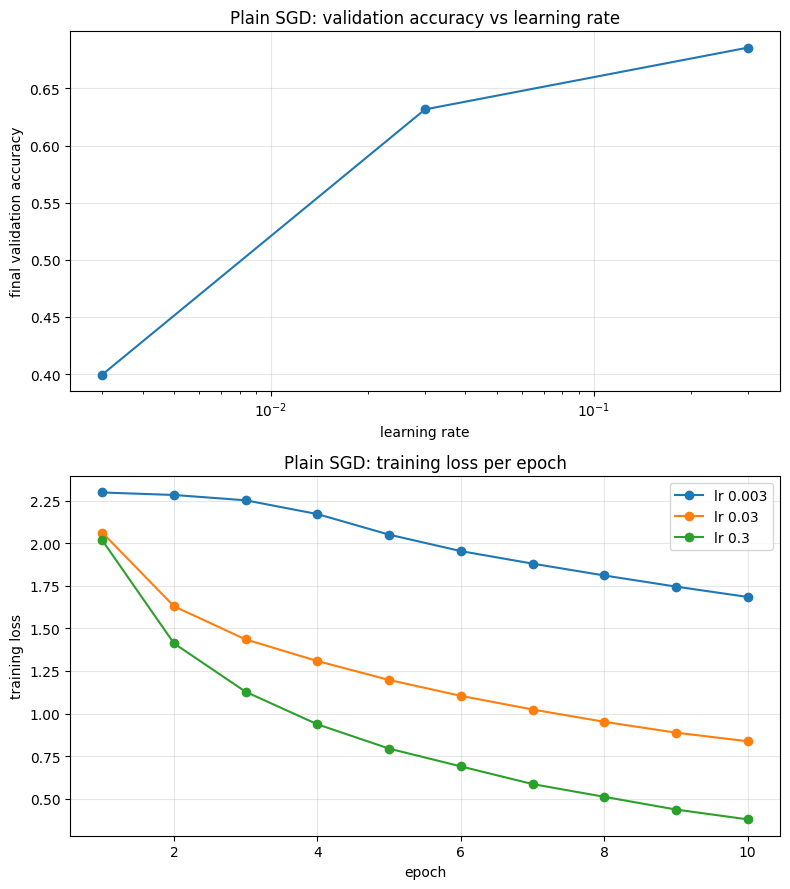

In [13]:
Xtr_d, ytr_d = Xtr.to(device), ytr.to(device)
Xva_d, yva_d = Xva.to(device), yva.to(device)

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 16x16
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 8x8
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 4x4
        nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, 10)
    ).to(device)

print("CNN parameters:", sum(p.numel() for p in make_cnn().parameters()))

@torch.no_grad()
def eval_val(model):
    model.eval()
    correct, tot_loss = 0, 0.0
    for i in range(0, len(Xva_d), 1000):
        out = model(Xva_d[i:i+1000])
        tot_loss += F.cross_entropy(out, yva_d[i:i+1000], reduction="sum").item()
        correct += (out.argmax(1) == yva_d[i:i+1000]).sum().item()
    return tot_loss / len(Xva_d), correct / len(Xva_d)

def train_cnn(opt_fn, epochs=10, bs=128):
    set_seed(SEED)
    model = make_cnn()
    opt = opt_fn(model.parameters())
    gen = torch.Generator().manual_seed(SEED)
    hist = dict(train_loss=[], val_loss=[], val_acc=[], diverged=False)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_d), generator=gen).to(device)
        run = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xtr_d[idx]), ytr_d[idx])
            loss.backward()
            opt.step()
            run += loss.item() * len(idx)
        tl = run / len(perm)
        if not np.isfinite(tl):
            hist["diverged"] = True
            break
        vl, va = eval_val(model)
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_acc"].append(va)
    return hist

results = {}          # keys: (optimizer name, lr)
sgd_lrs = [0.003, 0.03, 0.3]
for lr in sgd_lrs:
    results[("SGD", lr)] = train_cnn(lambda p: MySGD(p, lr=lr))

def summarize(name, lrs):
    print(f"{'lr':<10}{'final train loss':>18}{'final val acc':>15}{'best val acc':>14}")
    for lr in lrs:
        h = results[(name, lr)]
        if h["diverged"] or not h["val_acc"]:
            print(f"{lr:<10}{'diverged (NaN)':>18}{'-':>15}{'-':>14}")
        else:
            print(f"{lr:<10}{h['train_loss'][-1]:>18.4f}{h['val_acc'][-1]:>15.4f}{max(h['val_acc']):>14.4f}")

summarize("SGD", sgd_lrs)

fig, ax = plt.subplots(2, 1, figsize=(8, 9))
accs = [results[("SGD", lr)]["val_acc"][-1] if results[("SGD", lr)]["val_acc"] else 0.1 for lr in sgd_lrs]
ax[0].semilogx(sgd_lrs, accs, "o-")
ax[0].set_xlabel("learning rate"); ax[0].set_ylabel("final validation accuracy")
ax[0].set_title("Plain SGD: validation accuracy vs learning rate"); ax[0].grid(alpha=0.3)
for lr in sgd_lrs:
    h = results[("SGD", lr)]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", label=f"lr {lr}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
ax[1].set_title("Plain SGD: training loss per epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation (plain SGD).** A 357k-parameter CNN was trained for 10 epochs with plain SGD at learning rates 0.003, 0.03 and 0.3, from identical initial weights. Final validation accuracy rises monotonically with the learning rate: 39.96% (lr 0.003), 63.16% (lr 0.03) and 68.56% (lr 0.3), and the training loss at epoch 10 falls in the same order (1.68, 0.84, 0.38). At lr 0.003 the training loss stays near ln 10 ≈ 2.30 in the first epochs and is still decreasing almost linearly at epoch 10, so the model is undertrained: with a small step and no batch norm, the 10-epoch budget is far too short for it to converge. Each 10x increase in learning rate gives a large gain, so plain SGD is highly sensitive to the learning rate in this range, and the cost of choosing it too small is severe. The best rate among the three is 0.3, the largest value tried, and no divergence occurred, so the optimum may lie at or above 0.3 and this sweep does not bracket it. The validation accuracy of the lr 0.03 run is noisy across epochs (best 66.96%, final 63.16%), which is consistent with measurement noise on a 5,000-image validation set plus SGD's step-to-step variation. Learning rates were chosen by hand on a log grid and not tuned further.

SGD with momentum ($\mu = 0.9$) is trained with the same three learning rates as plain SGD, from the same initial weights.

lr          final train loss  final val acc  best val acc
0.003                 0.7931         0.6942        0.6942
0.03                  0.2788         0.7366        0.7368
0.3           diverged (NaN)              -             -


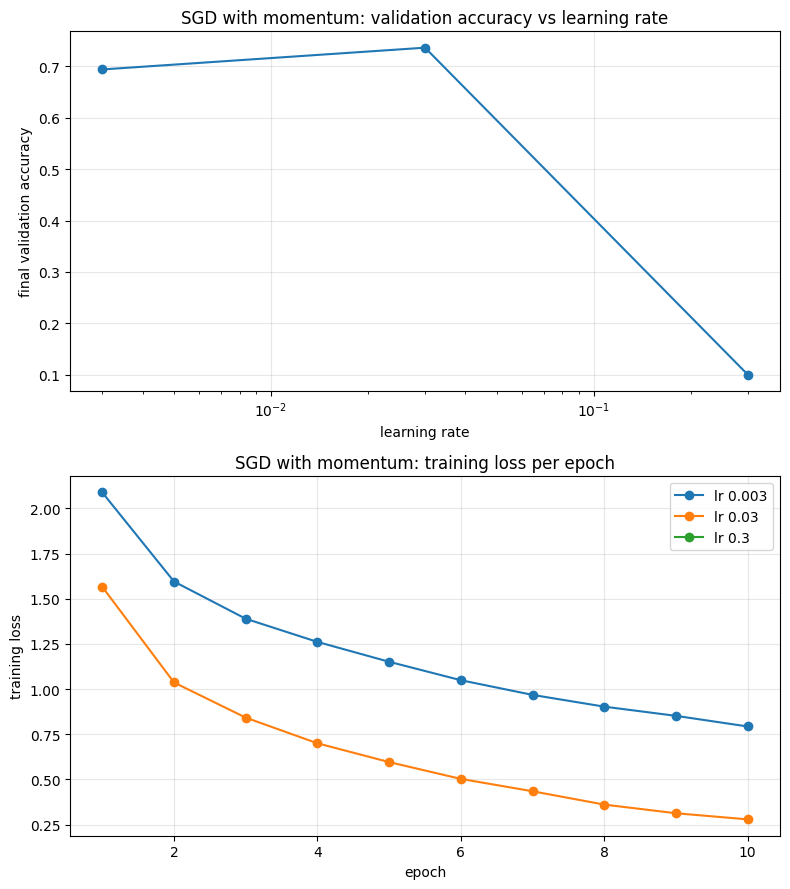

In [14]:
mom_lrs = [0.003, 0.03, 0.3]
for lr in mom_lrs:
    results[("SGD+momentum", lr)] = train_cnn(lambda p: MySGD(p, lr=lr, momentum=0.9))

summarize("SGD+momentum", mom_lrs)

fig, ax = plt.subplots(2, 1, figsize=(8, 9))
accs = [results[("SGD+momentum", lr)]["val_acc"][-1] if results[("SGD+momentum", lr)]["val_acc"] else 0.1
        for lr in mom_lrs]
ax[0].semilogx(mom_lrs, accs, "o-")
ax[0].set_xlabel("learning rate"); ax[0].set_ylabel("final validation accuracy")
ax[0].set_title("SGD with momentum: validation accuracy vs learning rate"); ax[0].grid(alpha=0.3)
for lr in mom_lrs:
    h = results[("SGD+momentum", lr)]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", label=f"lr {lr}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
ax[1].set_title("SGD with momentum: training loss per epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation (SGD with momentum, μ = 0.9).** With the same three learning rates, momentum reaches 69.42% (lr 0.003) and 73.66% (lr 0.03) validation accuracy, and diverges (NaN training loss) at lr 0.3. In the accuracy plot the diverged run is drawn at 0.1 (chance) by convention; no accuracy was measured. Momentum is clearly better than plain SGD at the same nominal rate (39.96% and 63.16% at 0.003 and 0.03), because it accumulates gradients into a larger effective step of about lr/(1−μ) = 10x the nominal lr, and it smooths the mini-batch noise. This is consistent with momentum at 0.003 giving a training loss (0.79) similar to plain SGD at 0.03 (0.84), although the match is only approximate. The same factor explains the divergence: at lr 0.3 the effective step is about 3, ten times larger than the largest rate plain SGD tolerated (0.3), so the training became unstable. Compared with plain SGD, whose accuracy rose with every 10x increase in lr over the tested range, momentum has an interior optimum at lr 0.03 and a cliff above it, so the usable range of learning rates is shifted roughly 10x lower and ends abruptly in divergence. The lr 0.003 run is still improving at epoch 10 (best = final), so it is limited by the 10-epoch budget. Only three learning rates were tried and the optimum lies somewhere between 0.003 and 0.3, so the best momentum rate is "best of three", not tuned.

lr          final train loss  final val acc  best val acc
0.003                 0.3676         0.7070        0.7220
0.03                  2.0135         0.2744        0.2974
0.3                   2.3212         0.1064        0.1064


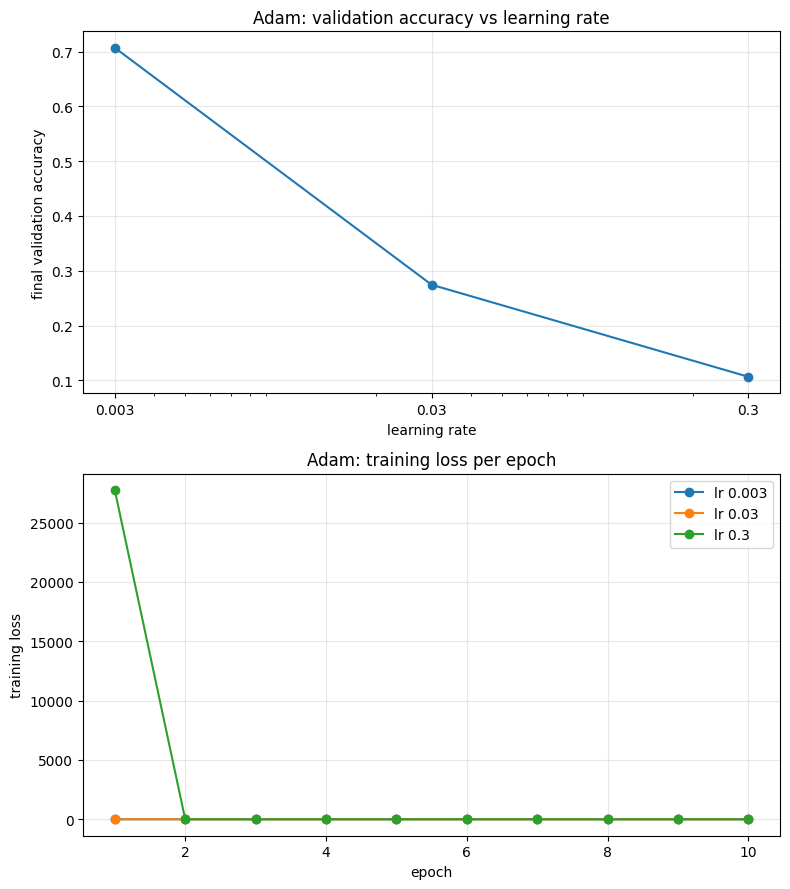

In [15]:
adam_lrs = [0.003, 0.03, 0.3]
for lr in adam_lrs:
    results[("Adam", lr)] = train_cnn(lambda p: MyAdam(p, lr=lr))

summarize("Adam", adam_lrs)

fig, ax = plt.subplots(2, 1, figsize=(8, 9))
accs = [results[("Adam", lr)]["val_acc"][-1] if results[("Adam", lr)]["val_acc"] else 0.1
        for lr in adam_lrs]
ax[0].semilogx(adam_lrs, accs, "o-")
ax[0].set_xticks(adam_lrs); ax[0].set_xticklabels([str(lr) for lr in adam_lrs])
ax[0].set_xlabel("learning rate"); ax[0].set_ylabel("final validation accuracy")
ax[0].set_title("Adam: validation accuracy vs learning rate"); ax[0].grid(alpha=0.3)
for lr in adam_lrs:
    h = results[("Adam", lr)]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", label=f"lr {lr}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
ax[1].set_title("Adam: training loss per epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation (Adam).** With the same three learning rates, Adam reaches 70.70% validation accuracy at lr 0.003 (best 72.20%), but only 27.44% at lr 0.03 (training loss 2.01) and 10.64% at lr 0.3 (training loss 2.32, essentially ln 10 ≈ 2.303, i.e. chance). Neither of the two larger rates produced a NaN, so these runs did not diverge numerically; they failed to learn. Adam's update divides the averaged gradient by the root of the averaged squared gradient, so each parameter moves by roughly the learning rate per step regardless of the gradient scale. Learning rates of 0.03 and 0.3 are therefore very large steps for every weight at once, and a likely explanation is that the network is pushed into a state where most ReLU units are inactive or the logits saturate, after which the gradients carry little useful signal. This explanation was not tested (for example by counting dead units), so it is a hypothesis. Adam is the most sensitive of the three optimizers in this sweep: accuracy falls from 70.7% to 27.4% to chance across two 10x increases, and its usable range is around 1e-3 or below, much lower than plain SGD's. The best Adam rate of the three tried is 0.003, which is also not tuned and may not be the optimum; a rate such as 0.001 was not tested. Adam at 0.003 did not beat SGD with momentum at 0.03 (73.66%) within 10 epochs.

optimizer               0.003          0.03           0.3   best lr
SGD                    39.96%        63.16%        68.56%       0.3
SGD+momentum           69.42%        73.66%      diverged      0.03
Adam                   70.70%        27.44%        10.64%     0.003


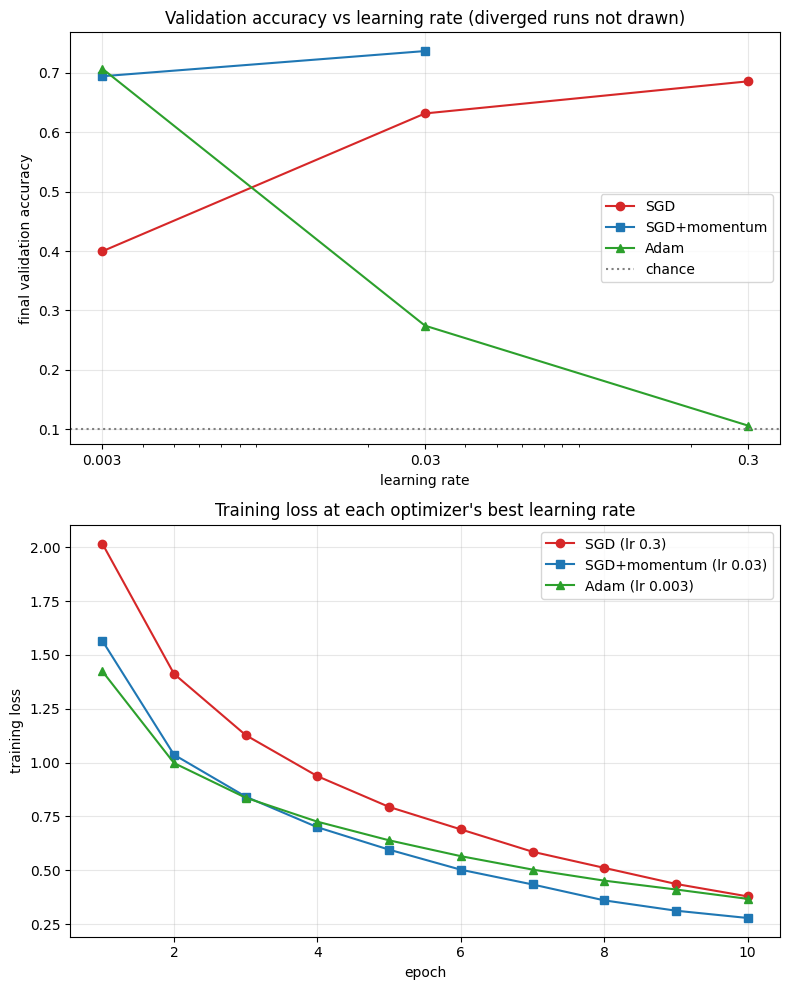

In [16]:
opt_names = ["SGD", "SGD+momentum", "Adam"]
lrs = [0.003, 0.03, 0.3]
styles = {"SGD": ("o-", "tab:red"), "SGD+momentum": ("s-", "tab:blue"), "Adam": ("^-", "tab:green")}

def final_acc(name, lr):
    h = results[(name, lr)]
    return h["val_acc"][-1] if h["val_acc"] else float("nan")   # diverged -> NaN (not plotted)

best = {n: max(lrs, key=lambda lr: (final_acc(n, lr) if np.isfinite(final_acc(n, lr)) else -1)) for n in opt_names}

print(f"{'optimizer':<15}" + "".join(f"{lr:>14}" for lr in lrs) + f"{'best lr':>10}")
for n in opt_names:
    row = "".join(f"{final_acc(n, lr)*100:>13.2f}%" if np.isfinite(final_acc(n, lr)) else f"{'diverged':>14}" for lr in lrs)
    print(f"{n:<15}{row}{best[n]:>10}")

fig, ax = plt.subplots(2, 1, figsize=(8, 10))
for n in opt_names:
    m, c = styles[n]
    ax[0].semilogx(lrs, [final_acc(n, lr) for lr in lrs], m, color=c, label=n)
ax[0].set_xticks(lrs); ax[0].set_xticklabels([str(lr) for lr in lrs])
ax[0].axhline(0.1, color="gray", ls=":", label="chance")
ax[0].set_xlabel("learning rate"); ax[0].set_ylabel("final validation accuracy")
ax[0].set_title("Validation accuracy vs learning rate (diverged runs not drawn)")
ax[0].legend(); ax[0].grid(alpha=0.3)

for n in opt_names:
    m, c = styles[n]
    h = results[(n, best[n])]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], m, color=c, label=f"{n} (lr {best[n]})")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
ax[1].set_title("Training loss at each optimizer's best learning rate"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Discussion: sensitivity to the learning rate.** The best learning rate differs by two orders of magnitude between optimizers: 0.3 for plain SGD (68.56%), 0.03 for SGD with momentum (73.66%) and 0.003 for Adam (70.70%). This follows from how each optimizer scales its step. Plain SGD moves by lr times the gradient, momentum accumulates gradients into an effective step of about lr/(1−μ) = 10x lr, which shifts its usable range roughly 10x lower, and Adam normalizes the gradient by its running RMS, so each weight moves by roughly lr per step and its usable range is lower still. Sensitivity shows up differently for each. Plain SGD is the most forgiving upward (no divergence up to 0.3) but pays heavily for a small rate: 39.96% at 0.003, because the training loss was still near ln 10 and the 10-epoch budget was too short.

# Task 3: Regularization and residual connections

## (a) Regularization with a small training set

A small CNN with batch norm is trained on the first 5,000 images of the 45k training split (validation is the same 5k split as before) for 60 epochs, using SGD with momentum (lr 0.03, μ = 0.9), batch size 128 and identical initial weights. Seven settings are compared: baseline, weight decay (5e-4), dropout (p = 0.5), flip+crop, cutout (16×16), mixup (α = 0.4) and all combined. Train accuracy is measured on the clean 5k images in eval mode, so the train-validation gap is not affected by augmentation.

class counts in 5k subset: [511, 510, 506, 509, 502, 472, 500, 470, 500, 520]
done: Baseline
done: Weight decay
done: Dropout
done: Flip+crop
done: Cutout
done: Mixup
done: All combined

setting          train acc   val acc     gap  best val  val loss
Baseline           100.00%    62.12%   37.88    62.92%     2.023
Weight decay       100.00%    62.38%   37.62    63.12%     1.749
Dropout             99.10%    64.90%   34.20    65.10%     1.269
Flip+crop           84.02%    68.88%   15.14    69.04%     0.961
Cutout              99.40%    63.68%   35.72    63.72%     1.523
Mixup               99.78%    61.60%   38.18    61.66%     1.199
All combined        61.40%    58.38%    3.02    59.68%     1.183


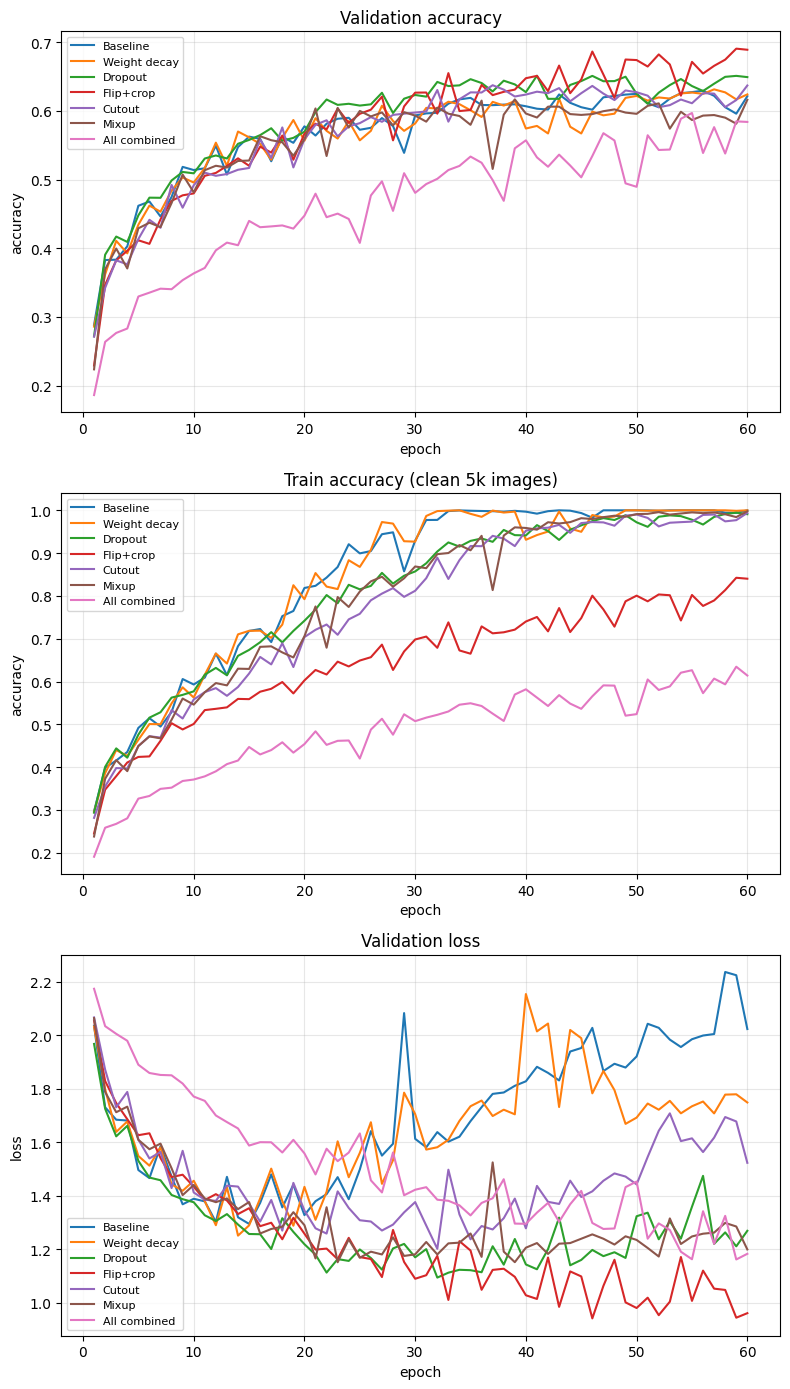

In [17]:
# ---------- data subset ----------
Xs, ys = Xtr_d[:5000], ytr_d[:5000]
print("class counts in 5k subset:", torch.bincount(ys.cpu()).tolist())

# ---------- augmentations (implemented by hand, on GPU tensors) ----------
def random_flip(x):
    flip = torch.rand(len(x), device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    N, C, H, W = x.shape
    xp = F.pad(x, (pad,) * 4)                                   # zero padding (= mean after normalization)
    dy = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    iy = (dy[:, None] + torch.arange(H, device=x.device))       # (N, H)
    ix = (dx[:, None] + torch.arange(W, device=x.device))       # (N, W)
    n = torch.arange(N, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n, c, iy[:, None, :, None], ix[:, None, None, :]]

def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device)
    cx = torch.randint(0, W, (N,), device=x.device)
    ys_ = torch.arange(H, device=x.device)[None, :, None]
    xs_ = torch.arange(W, device=x.device)[None, None, :]
    mask = ((ys_ >= (cy - size // 2)[:, None, None]) & (ys_ < (cy + size // 2)[:, None, None]) &
            (xs_ >= (cx - size // 2)[:, None, None]) & (xs_ < (cx + size // 2)[:, None, None]))
    return x * (~mask)[:, None, :, :]                           # masked region set to 0 (= mean)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

# ---------- model ----------
def make_bn_cnn(p_drop=0.0):
    def block(i, o):
        return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128),
                         nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 10)).to(device)

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), 1000):
        out = model(X[i:i+1000])
        loss += F.cross_entropy(out, y[i:i+1000], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i+1000]).sum().item()
    return loss / len(X), correct / len(X)

def train_reg(wd=0.0, p_drop=0.0, flipcrop=False, use_cutout=False, use_mixup=False,
              epochs=60, bs=128, lr=0.03):
    set_seed(SEED)
    model = make_bn_cnn(p_drop)
    opt = MySGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    gen = torch.Generator().manual_seed(SEED)
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xs), generator=gen).to(device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = Xs[idx], ys[idx]
            if flipcrop:
                xb = random_crop(random_flip(xb))
            if use_cutout:
                xb = cutout(xb)
            opt.zero_grad()
            if use_mixup:
                xb, ya, yb2, lam = mixup(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
            else:
                loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
        tl, ta = evaluate(model, Xs, ys)
        vl, va = evaluate(model, Xva_d, yva_d)
        h["train_loss"].append(tl); h["train_acc"].append(ta)
        h["val_loss"].append(vl);   h["val_acc"].append(va)
    return h

configs = {
    "Baseline":     dict(),
    "Weight decay": dict(wd=5e-4),
    "Dropout":      dict(p_drop=0.5),
    "Flip+crop":    dict(flipcrop=True),
    "Cutout":       dict(use_cutout=True),
    "Mixup":        dict(use_mixup=True),
    "All combined": dict(wd=5e-4, p_drop=0.5, flipcrop=True, use_cutout=True, use_mixup=True),
}
reg = {}
for name, kw in configs.items():
    reg[name] = train_reg(**kw)
    print("done:", name)

# ---------- table ----------
print(f"\n{'setting':<15}{'train acc':>11}{'val acc':>10}{'gap':>8}{'best val':>10}{'val loss':>10}")
for n, h in reg.items():
    ta, va = h["train_acc"][-1], h["val_acc"][-1]
    print(f"{n:<15}{ta*100:>10.2f}%{va*100:>9.2f}%{(ta-va)*100:>8.2f}{max(h['val_acc'])*100:>9.2f}%{h['val_loss'][-1]:>10.3f}")

# ---------- curves (stacked) ----------
ep = range(1, 61)
fig, ax = plt.subplots(3, 1, figsize=(8, 14))
for n, h in reg.items():
    ax[0].plot(ep, h["val_acc"], label=n)
    ax[1].plot(ep, h["train_acc"], label=n)
    ax[2].plot(ep, h["val_loss"], label=n)
for a, t, yl in zip(ax, ["Validation accuracy", "Train accuracy (clean 5k images)", "Validation loss"],
                    ["accuracy", "accuracy", "loss"]):
    a.set_title(t); a.set_xlabel("epoch"); a.set_ylabel(yl); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** On a 5k-image training set the baseline CNN with batch norm memorizes the data (100% train accuracy) and reaches 62.12% validation accuracy, a gap of 37.9 points, with validation loss of 2.02. Flip+crop is the most effective single regularizer: validation accuracy rises to 68.88% (+6.8 points) and the gap shrinks to 15.1 points, because random flips and shifts effectively enlarge the dataset with label-preserving variations, so the network cannot simply memorize fixed images (train accuracy on clean images falls to 84%). Dropout before the classifier gives a smaller gain (64.90%, validation loss 1.27). Weight decay (62.38%) and cutout (63.68%) change validation accuracy by less than about 1.6 points, which is close to the noise level of a single run on a 5k validation set (standard error about 0.65 points), so no reliable improvement can be claimed for them. Weight decay may help little because batch norm makes each layer's output invariant to the scale of its weights, so the L2 penalty mainly alters the effective learning rate rather than limiting capacity; this explanation was not tested here. Mixup does not improve accuracy (61.60%) but gives a much lower validation loss (1.20 vs 2.02), meaning it reduces overconfidence on wrong predictions without fixing the generalization gap within 60 epochs. Combining everything gives the smallest gap (3.0 points) but the lowest validation accuracy (58.38%) and only 61.4% training accuracy: the model underfits because five regularizers together are too strong for a small network and a 60-epoch budget. A small gap is therefore not the goal by itself, validation accuracy is. A milder combination, for example flip+crop with dropout, or training longer, might outperform flip+crop alone, but this was not tested. All settings use one seed, untuned shared hyperparameters (lr 0.03, wd 5e-4, dropout 0.5, cutout 16, mixup α 0.4), so differences of a point or two are not conclusive.

## (b) Plain vs residual networks of depth 6n+2

CIFAR-style networks of depth 8, 20 and 56 (n = 1, 3, 9) are built: a 3×3 conv (16 channels), three stages of n blocks with 16/32/64 channels, global average pooling and a linear layer, with batch norm and Kaiming initialization. Each block has two 3×3 convs. The only difference between the families is the shortcut: the residual block computes ReLU(F(x) + x), the plain block ReLU(F(x)). Downsampling shortcuts are parameter-free (stride-2 subsampling plus zero-padded channels), so both families have identical parameter counts. All six models use the same data, seed and settings (SGD, momentum 0.9, lr 0.1 with a 1-epoch warm-up, weight decay 1e-4, batch size 128, no augmentation, 20 epochs, fp16 mixed precision).

done (8, 'plain'): 50s, final train loss 0.3368
done (8, 'residual'): 52s, final train loss 0.3390
done (20, 'plain'): 117s, final train loss 0.2618
done (20, 'residual'): 123s, final train loss 0.1351
done (56, 'plain'): 323s, final train loss 0.6932
done (56, 'residual'): 337s, final train loss 0.1044

depth  family       params  final train loss  final val acc
8      plain         75290            0.3368         76.16%
8      residual      75290            0.3390         75.78%
20     plain        269722            0.2618         80.00%
20     residual     269722            0.1351         75.26%
56     plain        853018            0.6932         70.50%
56     residual     853018            0.1044         79.42%


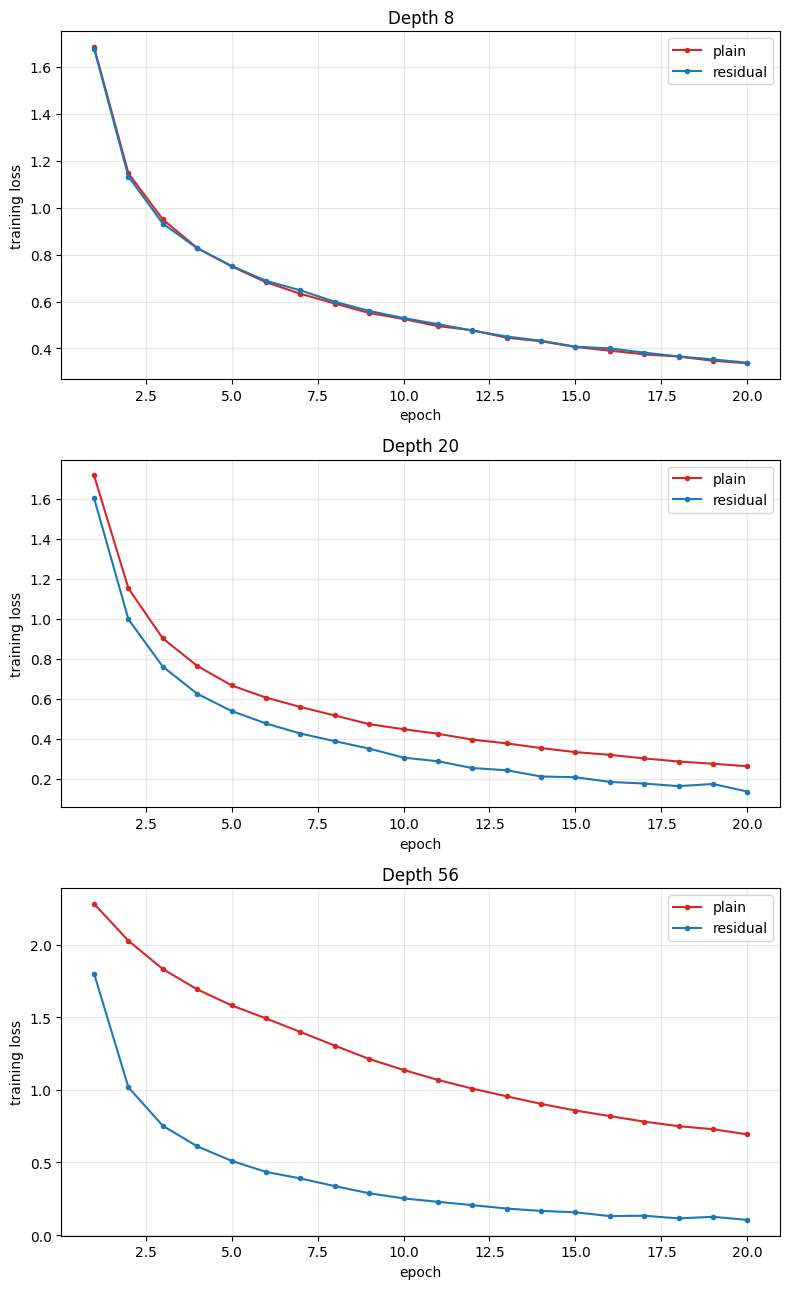

In [18]:
import time, math

class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.pad = residual, stride, (cout - cin) // 2

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:                                   # the ONLY difference between the families
            sc = x
            if self.stride != 1:                            # option A: no parameters
                sc = F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.pad, self.pad))
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual):
        super().__init__()
        self.conv = nn.Conv2d(3, 16, 3, 1, 1, bias=False); self.bn = nn.BatchNorm2d(16)
        layers, cin = [], 16
        for cout, stride in [(16, 1), (32, 2), (64, 2)]:
            for j in range(n):
                layers.append(Block(cin, cout, stride if j == 0 else 1, residual)); cin = cout
        self.stages = nn.Sequential(*layers)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():                            # Kaiming initialization
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.stages(x)
        return self.fc(x.mean(dim=(2, 3)))                  # global average pooling

def train_depth(depth, residual, epochs=20, bs=128, lr=0.1, wd=1e-4, warm_epochs=1):
    n = (depth - 2) // 6
    set_seed(SEED)
    model = CifarNet(n, residual).to(device)
    nparams = sum(p.numel() for p in model.parameters())
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    scaler = torch.amp.GradScaler("cuda")
    gen = torch.Generator().manual_seed(SEED)
    steps_ep = math.ceil(len(Xtr_d) / bs); it = 0
    h = dict(train_loss=[], val_acc=[], params=nparams, time=0.0, diverged=False)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_d), generator=gen).to(device)
        run = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            for g in opt.param_groups:
                g["lr"] = lr * min(1.0, (it + 1) / (warm_epochs * steps_ep))
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = F.cross_entropy(model(Xtr_d[idx]), ytr_d[idx])
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(idx); it += 1
        tl = run / len(perm)
        if not np.isfinite(tl):
            h["diverged"] = True; break
        h["train_loss"].append(tl)
        h["val_acc"].append(evaluate(model, Xva_d, yva_d)[1])
    h["time"] = time.time() - t0
    return h

depths = [8, 20, 56]
res = {}
for d in depths:
    for residual in (False, True):
        key = (d, "residual" if residual else "plain")
        res[key] = train_depth(d, residual)
        h = res[key]
        print(f"done {key}: {h['time']:.0f}s, final train loss {h['train_loss'][-1]:.4f}" if h["train_loss"] else f"{key}: diverged")
        torch.save(res, "res_3b.pt")                         # local backup (lost if the runtime resets)

# ---------- table ----------
print(f"\n{'depth':<7}{'family':<10}{'params':>9}{'final train loss':>18}{'final val acc':>15}")
for (d, fam), h in res.items():
    if h["train_loss"]:
        print(f"{d:<7}{fam:<10}{h['params']:>9}{h['train_loss'][-1]:>18.4f}{h['val_acc'][-1]*100:>14.2f}%")

# ---------- training loss vs epoch (stacked) ----------
fig, ax = plt.subplots(3, 1, figsize=(8, 13))
for a, d in zip(ax, depths):
    for fam, c in [("plain", "tab:red"), ("residual", "tab:blue")]:
        h = res[(d, fam)]
        a.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", ms=3, color=c, label=fam)
    a.set_title(f"Depth {d}"); a.set_xlabel("epoch"); a.set_ylabel("training loss"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

**Interpretation.** At depth 8 the plain and residual networks have almost identical training curves (final loss 0.337 vs 0.339), so the shortcut matters little in a shallow network. As depth grows the families separate. The plain network's final training loss goes 0.337 (depth 8), 0.262 (depth 20), 0.693 (depth 56): the 56-layer plain network trains much worse than the 8-layer one, although the extra layers could in principle represent identity maps, so adding depth made optimization harder. This is the degradation problem, and it is a training-loss effect, not overfitting. The residual network behaves the opposite way: 0.339, 0.135, 0.104, so deeper is better, and at depth 56 its loss is about 6.6x lower than the plain network's, with a lower loss from the first epoch. The shortcut explains this. In a residual block the output is ReLU(F(x)+x), so the gradient has a direct identity path to earlier layers and each block only has to learn a residual correction to its input, which is easier than learning a full mapping through 56 stacked nonlinear layers. Batch norm and Kaiming initialization already prevent the gradients of the plain network from vanishing completely, so the remaining failure is an optimization difficulty, which the shortcut removes; I did not measure gradient norms or test the mechanism directly. Validation accuracy does not follow training loss. At depth 56 residual is better (79.42% vs 70.50%), but at depth 20 plain is better (80.00% vs 75.26%) despite a training loss twice as high. A likely reason is that the better-fitting residual network overfits more, as no data augmentation was used, but I did not test this. Caveats: single seed, 20 epochs, constant learning rate after warm-up, and the plain-56 curve is still decreasing steeply at epoch 20, so its gap measures speed of optimization within this budget and not a final limit. Training loss is the running average during each epoch in train mode.